# 1. Installation and Configuration of Required Libraries

## 1.1 Introduction

The initial stage of the Speech Emotion Recognition (SER) project involved setting up the Google Colab development environment and installing the Python libraries required for audio processing, data analysis, feature extraction, visualisation and deep learning.

These libraries provide the necessary tools for processing speech recordings, extracting relevant acoustic features and developing machine learning and deep learning models for emotion classification.

## 1.2 Required Libraries

The following Python libraries were used in the project:

| Library | Purpose |
|---|---|
| Librosa | Audio loading and feature extraction |
| SoundFile | Reading and writing audio files |
| NumPy | Numerical computations and array processing |
| Pandas | Dataset organisation and manipulation |
| Scikit-learn | Data preprocessing and model evaluation |
| Matplotlib | Data visualisation |
| Seaborn | Statistical visualisation |
| PyTorch | Deep learning and neural network development |
| TQDM | Monitoring training progress |

## 1.3 Installation of Required Libraries

The following command installs the required dependencies in the Google Colab environment.

In [1]:
!pip install librosa soundfile numpy pandas \
scikit-learn matplotlib seaborn torch tqdm

## 1.4 Importing Libraries and Checking the Computing Environment

After installation, the necessary libraries were imported, and the PyTorch and Librosa versions were checked.

The computing environment was also examined to determine whether GPU acceleration was available.



In [2]:
import torch
import librosa
import numpy as np

print("PyTorch:", torch.__version__)
print("Librosa:", librosa.__version__)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)


PyTorch: 2.14.1+cpu
Librosa: 0.11.0
Using device: cpu


## 1.5 Results and Analysis

The installation process completed successfully. The output indicated that the required libraries were already available in the Google Colab environment.

The reported library versions included:

- Librosa: 0.11.0
- NumPy: 2.4.6
- Pandas: 2.2.3
- Scikit-learn: 1.6.1
- Matplotlib: 3.10.0
- Seaborn: 0.13.2
- PyTorch: 2.14.1
- TQDM: 4.67.3

The computing environment was also checked to identify the available processing device.

The successful verification established that the required software dependencies were accessible for subsequent stages of the project.

In [5]:
import zipfile
from pathlib import Path
from src.config import DATA_DIR

ZIP_PATH = Path("/content/Audio_Speech_Actors_01-24.zip")

DATA_DIR.mkdir(parents=True, exist_ok=True)

if not any(DATA_DIR.rglob("*.wav")):
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(DATA_DIR)

print("Dataset location:", DATA_DIR)
print("Dataset extraction complete.")
print("Audio files:", len(list(DATA_DIR.rglob("*.wav"))))

Dataset location: /content/data/RAVDESS
Dataset extraction complete.
Audio files: 1440


# 2. RAVDESS Dataset Extraction

## 2.1 Introduction

The Ryerson Audio-Visual Database of Emotional Speech and Song (RAVDESS) was selected as the dataset for developing the Speech Emotion Recognition system.

The dataset contains speech recordings representing different emotional expressions. Before processing the recordings, the compressed dataset needed to be extracted into the project's designated data directory.

The extraction process was implemented using Python's `zipfile` and `pathlib` libraries.

## 2.2 Dataset Extraction Code

The following code extracts the compressed RAVDESS dataset into the designated project directory.

This code extracts the compressed RAVDESS audio dataset from the ZIP archive into the designated dataset directory.

The zipfile library handles the extraction process, while the os library provides access to the extracted directory structure.

After extraction, the code displays a selection of the available actor folders to verify that the dataset files have been successfully unpacked and are accessible.

In [10]:
from src.config import DATA_DIR, MODEL_DIR, RESULTS_DIR

from pathlib import Path

# Display dataset location
print("Dataset location:", DATA_DIR)

# Identify actor directories
actor_dirs = sorted([
    folder for folder in DATA_DIR.iterdir()
    if folder.is_dir() and folder.name.startswith("Actor_")
])

# Display extracted actor directories
print("\nExtracted actor directories:")

for folder in actor_dirs:
    print(folder.name)

# Display extraction summary
print("\nDataset verification:")
print("Total actor directories:", len(actor_dirs))
print("Total audio recordings:", len(list(DATA_DIR.rglob("*.wav"))))

Dataset location: /content/data/RAVDESS

Extracted actor directories:
Actor_01
Actor_02
Actor_03
Actor_04
Actor_05
Actor_06
Actor_07
Actor_08
Actor_09
Actor_10
Actor_11
Actor_12
Actor_13
Actor_14
Actor_15
Actor_16
Actor_17
Actor_18
Actor_19
Actor_20
Actor_21
Actor_22
Actor_23
Actor_24

Dataset verification:
Total actor directories: 24
Total audio recordings: 1440


## 2.3 Results and Analysis

Dataset Extraction and Verification Analysis

The RAVDESS (Ryerson Audio-Visual Database of Emotional Speech and Song) dataset was successfully extracted into the Google Colab local storage environment.

The extracted dataset is located at /content/data/RAVDESS.

The verification process identified 24 actor directories, ranging from Actor_01 to Actor_24, containing a total of 1,440 WAV audio recordings.

Dataset Verification Results
Description	Result
Total actor directories	24
Total audio recordings	1,440
Audio file format	WAV
Extraction status	Successful
Analysis and Observations
Successful extraction: The dataset was extracted without errors, and its directory structure is accessible.
Actor distribution: All 24 actor directories were identified, indicating that recordings from all expected actors are represented in the extracted directory structure.
Audio accessibility: A total of 1,440 WAV recordings were detected, confirming that the audio files are available for subsequent processing.
Dataset organisation: The recordings are organised into individual actor directories, providing a structured basis for data exploration and analysis.
Conclusion

The dataset extraction and initial verification were completed successfully. The presence of all 24 actor directories and 1,440 accessible audio recordings establishes the foundation for the next stages of the project, including exploratory data analysis (EDA), audio preprocessing, feature extraction, and emotion classification.

Note: This verification confirms the presence of the expected actor directories and audio files. Further analysis is required to examine emotion labels, class distribution, recording characteristics, and potential data quality issues.

# 3. Audio Loading and Waveform Visualisation

## 3.1 Introduction

After extracting the dataset, an initial examination of the audio recordings was conducted to verify that the speech files could be accessed and processed.

Librosa was used to load the audio recordings, while Matplotlib was used to visualise the waveform.

The selected recording was resampled to 22,050 Hz to provide a consistent sampling rate for subsequent audio processing.

The duration of the recording was calculated using the number of audio samples divided by the sampling rate.


## 3.2 Audio Loading and Visualisation Code

The following code identifies the available WAV recordings, selects a sample audio file, loads it using Librosa and generates a waveform visualisation.

Total audio files: 1440
Sample rate: 22050
Audio duration: 3.436780045351474


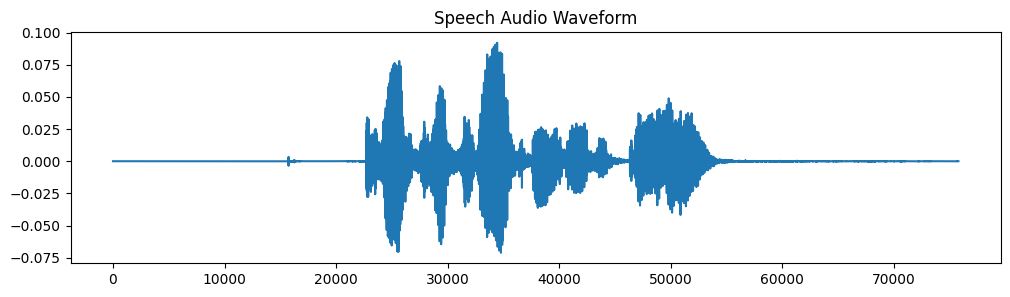

In [11]:
import librosa
import matplotlib.pyplot as plt
from pathlib import Path

audio_files = list(
    Path(DATA_DIR).rglob("*.wav")
)

print("Total audio files:", len(audio_files))

sample_file = audio_files[0]

audio, sr = librosa.load(
    str(sample_file),
    sr=22050
)

print("Sample rate:", sr)
print("Audio duration:", len(audio) / sr)

plt.figure(figsize=(12, 3))
plt.plot(audio)
plt.title("Speech Audio Waveform")
plt.show()


## 3.3 Results and Analysis

The audio loading and waveform visualisation process executed successfully.

The code identified the available WAV recordings and selected one audio file for initial inspection.

The recording was successfully loaded using Librosa at a sampling rate of 22,050 Hz.

The waveform visualisation provided a graphical representation of the speech signal, illustrating variations in signal amplitude throughout the recording.

This visual representation assists in understanding the structure of the audio signal and provides an initial indication of the acoustic characteristics of the speech recording.

The successful execution of this stage confirmed that the audio recordings could be accessed and processed using Librosa.

# 4. Mel-Frequency Cepstral Coefficients (MFCC) Extraction and Visualisation

## 4.1 Introduction

Mel-Frequency Cepstral Coefficients (MFCCs) are commonly used acoustic features in speech processing and speech emotion recognition.

They provide a compact representation of the spectral envelope of an audio signal, capturing characteristics associated with speech sounds.

In this stage, 40 MFCC coefficients were extracted from the previously loaded audio recording using Librosa.

The resulting features were visualised to examine how the spectral characteristics of the speech signal changed over time.

## 4.2 MFCC Extraction Code

The following code extracts 40 MFCC coefficients from the selected audio recording and generates a visual representation of the extracted features.

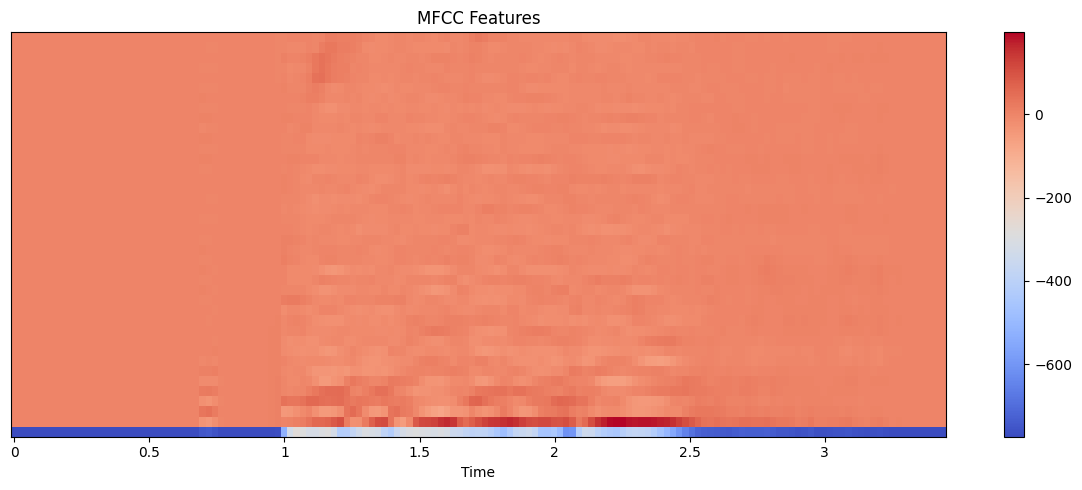

In [13]:
import librosa
import librosa.display
import matplotlib.pyplot as plt

mfcc = librosa.feature.mfcc(
    y=audio,
    sr=sr,
    n_mfcc=40
)

plt.figure(figsize=(12, 5))

librosa.display.specshow(
    mfcc,
    x_axis="time",
    sr=sr
)

plt.colorbar()
plt.title("MFCC Features")
plt.tight_layout()
plt.show()


## 4.3 Results and Analysis

The MFCC extraction and visualisation process executed successfully.

The resulting visualisation displayed 40 MFCC coefficients across the duration of the selected speech recording.

The visualisation demonstrated variations in the extracted acoustic features over time.

MFCCs are useful in speech emotion recognition because they capture important spectral characteristics that may help distinguish between different emotional expressions.

The successful extraction of these coefficients demonstrated that the audio recordings could be transformed into numerical acoustic features for subsequent machine learning and deep learning applications.

# 5. Testing the Custom Audio Preprocessing Function

## 5.1 Introduction

Following the initial MFCC extraction, the project's custom audio preprocessing function was tested to verify that speech recordings could be transformed into structured numerical feature representations.

The `extract_features()` function, implemented in the project's `src.preprocessing` module, was applied to the selected audio recording.

The resulting feature array was examined to determine its dimensions, numerical data type and whether it contained any invalid numerical values.

These checks were important for establishing the suitability of the extracted features for subsequent dataset preparation and model development.

In [18]:
import os
from src.preprocessing import extract_features

print(os.path.exists("/content/src"))
print(os.listdir("/content/src") if os.path.exists("/content/src") else "src folder missing")

True
['config.py', '__pycache__', '.ipynb_checkpoints', 'preprocessing.py']


## 5.2 Preprocessing Code

The following code tests the custom preprocessing function and examines the resulting feature array.

In [19]:


features = extract_features(str(sample_file))

print("Feature shape:", features.shape)
print("Data type:", features.dtype)
print("Contains NaN:", np.isnan(features).any())


Feature shape: (64, 302)
Data type: float32
Contains NaN: False



## 5.3 Results and Analysis

The custom preprocessing function executed successfully without errors.

The following results were obtained:

| Validation | Result |
|---|---|
| Feature shape | (64, 302) |
| Data type | float32 |
| Contains NaN values | False |
| Function execution | Successful |

The feature shape of (64, 302) indicates that the preprocessing function generated a two-dimensional numerical array containing 64 feature dimensions and 302 time frames.

The `float32` data type indicates that the extracted features were stored using 32-bit floating-point values, which are suitable for numerical processing and deep learning applications.

The result `False` for the NaN check confirms that the extracted feature array did not contain any Not a Number values.

These results demonstrate that the custom preprocessing function successfully transformed the selected audio recording into a structured numerical representation.

The extracted features can therefore be used in subsequent dataset preparation and emotion classification stages, subject to further validation across the complete dataset.


# 6. Overall Exploratory Data Analysis Summary

The exploratory data analysis stage established the development environment and verified the initial processing of the RAVDESS speech audio dataset.

The required Python libraries were installed or confirmed to be available within Google Colab. The computing environment was also checked to identify the available processing device.

The RAVDESS dataset was extracted into the designated project directory, and the extracted actor folders were inspected to verify dataset accessibility.

An initial audio loading test was conducted using Librosa. The selected speech recording was successfully loaded at a sampling rate of 22,050 Hz, and its waveform was visualised using Matplotlib.

Furthermore, 40 Mel-Frequency Cepstral Coefficients were extracted to examine the spectral characteristics of the speech signal. This demonstrated the ability to transform raw audio recordings into meaningful acoustic representations.

Finally, the custom preprocessing function was tested and generated a feature array with dimensions of 64 × 302. The extracted features were stored as `float32` values, and no NaN values were detected.

Overall, the exploratory analysis confirmed the successful execution of the initial environment setup, dataset extraction, audio loading, MFCC extraction and custom feature preprocessing procedures.

These findings provide a foundation for the next phase of the Speech Emotion Recognition project, which will involve processing the complete dataset, preparing the extracted features, developing the classification model, training the neural network and evaluating its performance.